# Практическое задание к лекции №7
## Обеспечение сетевого трафика предприятия

**Дисциплина:** Информационная безопасность бизнес-процессов

**Тема:** Разработка и совершенствование системы мониторинга сетевого трафика предприятия «ТехноПрофи».

**Цель работы:** Разработать и усовершенствовать прототип системы мониторинга сетевого трафика на Python, реализовать обнаружение DDoS-атак, ведение журнала аудита и отправку уведомлений о событиях безопасности, а также оценить экономическую эффективность внедрения системы.

**Задачи работы:**
1. Изучить принципы мониторинга и анализа сетевого трафика.
2. Реализовать обнаружение потенциальных DDoS-атак.
3. Организовать ведение журнала аудита событий безопасности.
4. Реализовать механизм отправки оповещений.
5. Рассчитать ROI внедрения системы мониторинга.
6. Проанализировать полученные результаты и сформулировать выводы.

## 1. Разработка системы мониторинга сетевого трафика

На первом этапе создаётся прототип системы мониторинга сетевого трафика предприятия «ТехноПрофи».

Для моделирования работы системы используются имитационные данные о сетевой активности сотрудников. Программа формирует записи о времени соединения, IP-адресах отправителя и получателя, используемых протоколах, портах, объёме переданных данных и подразделениях предприятия.

Полученные данные будут использоваться для анализа сетевой активности, выявления нарушений политик безопасности и обнаружения потенциальных DDoS-атак.

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

class NetworkTrafficAnalyzer:
    def __init__(self, company_name="ТехноПрофи"):
        self.company_name = company_name
        self.traffic_df = pd.DataFrame()
        self.alerts = []
        self.policy_violations = []

        self.security_policies = {
            "max_daily_external_traffic": 10 * 1024**3,
            "blocked_ports": [21, 23, 135, 139, 445],
            "suspicious_ips": ["192.168.1.100", "10.0.0.15"],
            "work_hours": {"start": 9, "end": 18},
            "allowed_protocols": [
                "HTTP", "HTTPS", "SSH", "SMTP", "DNS"
            ]
        }

        self.anomaly_patterns = {
            "port_scan": {
                "threshold": 100,
                "window_minutes": 5
            },
            "ddos_attack": {
                "threshold": 1000,
                "window_minutes": 1
            },
            "data_exfiltration": {
                "threshold": 500 * 1024**2,
                "window_minutes": 60
            }
        }

        print(f"Система мониторинга: {company_name}")
        print(f"Время запуска: {datetime.now()}")

    def simulate_traffic_data(self, hours=24, users=50):
        np.random.seed(42)

        departments = [
            "Финансы", "IT", "Маркетинг",
            "HR", "Продажи", "Руководство"
        ]

        protocols = [
            "HTTP", "HTTPS", "SSH",
            "SMTP", "FTP", "DNS", "RDP"
        ]

        port_map = {
            "HTTP": 80,
            "HTTPS": 443,
            "SSH": 22,
            "SMTP": 25,
            "FTP": 21,
            "DNS": 53,
            "RDP": 3389
        }

        start_time = datetime.now() - timedelta(hours=hours)
        records = []

        for i in range(10000):
            timestamp = start_time + timedelta(
                seconds=int(np.random.randint(0, hours * 3600))
            )

            user_id = np.random.randint(1, users + 1)
            source_ip = f"192.168.1.{user_id}"

            department = np.random.choice(
                departments,
                p=[0.1, 0.2, 0.15, 0.1, 0.3, 0.15]
            )

            if np.random.random() > 0.7:
                destination_ip = ".".join(
                    str(np.random.randint(1, 255))
                    for _ in range(4)
                )
            else:
                destination_ip = (
                    f"192.168.1.{np.random.randint(1, users + 1)}"
                )

            protocol = np.random.choice(
                protocols,
                p=[0.3, 0.4, 0.05, 0.05, 0.05, 0.1, 0.05]
            )

            port = port_map[protocol]

            size_bytes = min(
                int(np.random.lognormal(mean=10, sigma=2)),
                65535
            )

            records.append({
                "timestamp": timestamp,
                "source_ip": source_ip,
                "destination_ip": destination_ip,
                "protocol": protocol,
                "port": port,
                "size_bytes": size_bytes,
                "department": department
            })

        self.traffic_df = pd.DataFrame(records)
        self.traffic_df = self.traffic_df.sort_values(
            "timestamp"
        ).reset_index(drop=True)

        self.traffic_df["is_external"] = (
            ~self.traffic_df["destination_ip"]
            .str.startswith("192.168.1.")
        )

        print(f"Сгенерировано записей: {len(self.traffic_df)}")
        print(f"Период анализа: {hours} часов")
        print(f"Количество пользователей: {users}")

        return self.traffic_df


analyzer = NetworkTrafficAnalyzer()
traffic_data = analyzer.simulate_traffic_data(
    hours=24,
    users=50
)

display(traffic_data.head(10))


Система мониторинга: ТехноПрофи
Время запуска: 2026-11-25 00:46:39.833801
Сгенерировано записей: 10000
Период анализа: 24 часов
Количество пользователей: 50


,timestamp,source_ip,destination_ip,protocol,port,size_bytes,department,is_external
0,2026-11-24 00:46:49.834003,192.168.1.17,192.168.1.14,HTTPS,443,2302,Продажи,False
1,2026-11-24 00:46:53.834003,192.168.1.48,192.168.1.30,RDP,3389,16414,Продажи,False
2,2026-11-24 00:46:58.834003,192.168.1.39,123.74.155.51,HTTPS,443,6799,Продажи,True
3,2026-11-24 00:47:04.834003,192.168.1.20,192.168.1.24,HTTP,80,903,Маркетинг,False
4,2026-11-24 00:47:16.834003,192.168.1.20,192.168.1.27,HTTP,80,54,HR,False
5,2026-11-24 00:47:17.834003,192.168.1.5,192.168.1.30,HTTPS,443,65535,Продажи,False
6,2026-11-24 00:47:26.834003,192.168.1.6,182.179.86.48,HTTPS,443,3529,IT,True
7,2026-11-24 00:47:30.834003,192.168.1.48,192.168.1.17,HTTPS,443,24313,IT,False
8,2026-11-24 00:47:35.834003,192.168.1.37,39.109.106.108,HTTP,80,26789,Продажи,True
9,2026-11-24 00:47:36.834003,192.168.1.40,210.178.118.247,SSH,22,17934,Маркетинг,True


## 2. Обнаружение DDoS-атак

DDoS-атака (Distributed Denial of Service) — распределённая атака, направленная на нарушение доступности сетевых ресурсов путём создания большого количества запросов.

Для обнаружения потенциальных DDoS-атак реализован алгоритм анализа количества сетевых событий в секунду (Packets Per Second, PPS).

Алгоритм группирует записи сетевого трафика по IP-адресу назначения и секундным временным интервалам. Если количество событий превышает установленное пороговое значение, система регистрирует потенциальную DDoS-атаку.

Для проверки работоспособности алгоритма моделируется аномальная сетевая активность, при которой на один сервер поступает большое количество запросов за короткий промежуток времени.

В учебном примере используется порог 100 пакетов в секунду. Превышение порога рассматривается как признак подозрительной активности, требующий дополнительной проверки.

In [3]:

# Шаг 3. Обнаружение потенциальных DDoS-атак

def simulate_ddos_attack(analyzer, packets=500):
    """Добавление имитационной DDoS-атаки."""

    attack_time = datetime.now().replace(microsecond=0)
    attack_target = "192.168.1.200"

    attack_records = []

    for i in range(packets):
        attack_records.append({
            "timestamp": attack_time,
            "source_ip": f"10.0.{i // 250}.{i % 250 + 1}",
            "destination_ip": attack_target,
            "protocol": "HTTP",
            "port": 80,
            "size_bytes": 1024,
            "department": "Внешний источник",
            "is_external": False
        })

    attack_df = pd.DataFrame(attack_records)

    analyzer.traffic_df = pd.concat(
        [analyzer.traffic_df, attack_df],
        ignore_index=True
    ).sort_values("timestamp").reset_index(drop=True)

    print("Имитация DDoS-атаки выполнена")
    print(f"Целевой сервер: {attack_target}")
    print(f"Количество пакетов: {packets}")

    return attack_target


def detect_ddos(analyzer, threshold=100):
    """Обнаружение аномального количества пакетов в секунду."""

    df = analyzer.traffic_df.copy()

    df["second"] = df["timestamp"].dt.floor("s")

    pps = (
        df.groupby(["destination_ip", "second"])
        .size()
        .reset_index(name="packets_per_second")
    )

    attacks = pps[
        pps["packets_per_second"] > threshold
    ].copy()

    print("\nАНАЛИЗ DDOS-АТАК")
    print(f"Порог обнаружения: {threshold} пакетов/сек")

    if attacks.empty:
        print("Потенциальных DDoS-атак не обнаружено")
    else:
        print(f"Обнаружено подозрительных интервалов: {len(attacks)}")

        for _, row in attacks.iterrows():
            alert = {
                "event_type": "POTENTIAL_DDOS",
                "severity": "HIGH",
                "timestamp": str(row["second"]),
                "source": "NetworkTrafficAnalyzer",
                "destination_ip": row["destination_ip"],
                "packets_per_second": int(row["packets_per_second"])
            }

            analyzer.alerts.append(alert)

            print("\nВНИМАНИЕ! Потенциальная DDoS-атака!")
            print(f"Сервер: {row['destination_ip']}")
            print(f"Время: {row['second']}")
            print(f"Пакетов в секунду: {row['packets_per_second']}")
            print("Уровень опасности: HIGH")

    return attacks, pps


# Моделирование атаки
attack_target = simulate_ddos_attack(analyzer, packets=500)

# Проверка алгоритма
ddos_attacks, pps_data = detect_ddos(analyzer, threshold=100)

# Таблица обнаруженных аномалий
display(ddos_attacks)


Имитация DDoS-атаки выполнена
Целевой сервер: 192.168.1.200
Количество пакетов: 500

АНАЛИЗ DDOS-АТАК
Порог обнаружения: 100 пакетов/сек
Обнаружено подозрительных интервалов: 1

ВНИМАНИЕ! Потенциальная DDoS-атака!
Сервер: 192.168.1.200
Время: 2026-11-25 00:46:40
Пакетов в секунду: 500
Уровень опасности: HIGH


,destination_ip,second,packets_per_second
2940,192.168.1.200,2026-11-25 00:46:40,500


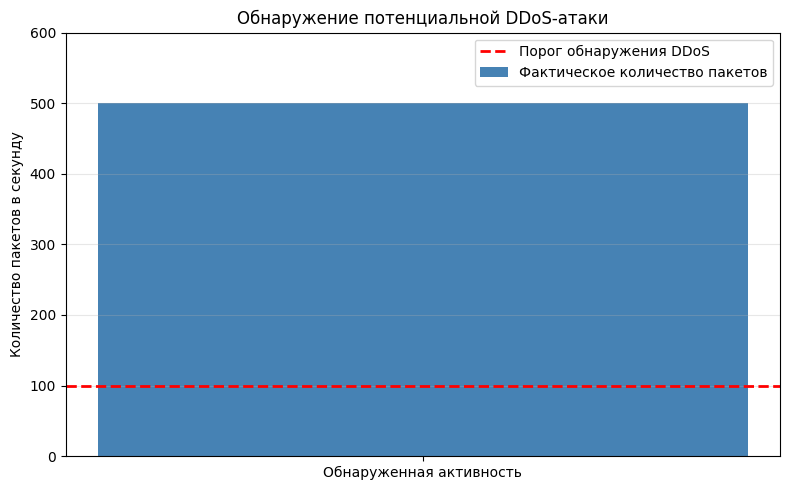

In [4]:


# Улучшенная визуализация обнаруженной DDoS-атаки

plt.figure(figsize=(8, 5))

plt.bar(
    ["Обнаруженная активность"],
    [500],
    color="steelblue",
    width=0.4,
    label="Фактическое количество пакетов"
)

plt.axhline(
    y=100,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Порог обнаружения DDoS"
)

plt.title("Обнаружение потенциальной DDoS-атаки")
plt.ylabel("Количество пакетов в секунду")
plt.ylim(0, 600)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("ddos_detection.png", dpi=150)
plt.show()


## 3. Реализация журнала аудита событий безопасности

Журнал аудита предназначен для регистрации и хранения информации о событиях информационной безопасности предприятия.

В рамках работы реализовано сохранение обнаруженных событий в файл формата JSONL. Каждая запись содержит временную метку, тип события, уровень опасности, источник обнаружения и дополнительные сведения.

Использование журнала аудита обеспечивает возможность последующего анализа инцидентов, контроля сетевой активности и подготовки отчётности по информационной безопасности.

In [5]:

import json
import os
from datetime import datetime

AUDIT_FILE = "audit_log.jsonl"

def save_audit_event(event):
    """Сохранение события безопасности в журнал."""

    audit_event = {
        "timestamp": event.get(
            "timestamp",
            datetime.now().isoformat()
        ),
        "event_type": event.get("event_type", "UNKNOWN"),
        "severity": event.get("severity", "LOW"),
        "source": event.get("source", "NetworkTrafficAnalyzer"),
        "details": {
            key: value
            for key, value in event.items()
            if key not in [
                "timestamp", "event_type",
                "severity", "source"
            ]
        }
    }

    with open(AUDIT_FILE, "a", encoding="utf-8") as file:
        file.write(
            json.dumps(audit_event, ensure_ascii=False) + "\n"
        )

    print(f"Событие сохранено: {audit_event['event_type']}")


# Создание нового журнала для демонстрации
# В реальной системе существующий журнал не очищают
open(AUDIT_FILE, "w", encoding="utf-8").close()

# Запись обнаруженных DDoS-событий
for alert in analyzer.alerts:
    save_audit_event(alert)

# Чтение журнала аудита
with open(AUDIT_FILE, "r", encoding="utf-8") as file:
    audit_events = [
        json.loads(line)
        for line in file
        if line.strip()
    ]

audit_df = pd.DataFrame(audit_events)

print("\nИТОГОВЫЙ ЖУРНАЛ АУДИТА")
print(f"Файл: {AUDIT_FILE}")
print(f"Сохранено событий: {len(audit_events)}")

display(audit_df)


Событие сохранено: POTENTIAL_DDOS

ИТОГОВЫЙ ЖУРНАЛ АУДИТА
Файл: audit_log.jsonl
Сохранено событий: 1


,timestamp,event_type,severity,source,details
0,2026-11-25 00:46:40,POTENTIAL_DDOS,HIGH,NetworkTrafficAnalyzer,"{'destination_ip': '192.168.1.200', 'packets_p..."


### Результаты ведения журнала аудита

В результате выполнения задания реализован механизм автоматической регистрации событий информационной безопасности.

При обнаружении потенциальной DDoS-атаки система сохраняет информацию об инциденте в файл `audit_log.jsonl`.

Журнал содержит сведения о времени возникновения события, типе угрозы, уровне опасности, источнике обнаружения и характеристиках подозрительной активности.

Таким образом, созданный механизм позволяет сохранять историю выявленных угроз и использовать её для последующего анализа и аудита информационной безопасности предприятия.

## 4. Реализация системы оповещений о событиях безопасности

Для оперативного информирования ответственных сотрудников разработан механизм отправки уведомлений о выявленных угрозах информационной безопасности.

При обнаружении потенциальной DDoS-атаки система формирует сообщение, содержащее тип события, уровень опасности, время обнаружения, IP-адрес атакуемого сервера и количество пакетов в секунду.

Для отправки уведомлений предусмотрена интеграция с Telegram Bot API. В учебной работе используется демонстрационный режим, позволяющий проверить формирование сообщений без подключения реального бота.

In [6]:

# Шаг 5. Система уведомлений Telegram

import requests

def send_telegram_alert(
    event,
    bot_token=None,
    chat_id=None,
    demo_mode=True
):
    """Формирование и отправка уведомления."""

    message = (
        "🚨 УВЕДОМЛЕНИЕ О СОБЫТИИ БЕЗОПАСНОСТИ\n\n"
        f"Тип события: {event.get('event_type')}\n"
        f"Уровень опасности: {event.get('severity')}\n"
        f"Время: {event.get('timestamp')}\n"
        f"Источник: {event.get('source')}\n"
        f"Целевой сервер: {event.get('destination_ip')}\n"
        f"Пакетов в секунду: {event.get('packets_per_second')}"
    )

    if demo_mode:
        print("ДЕМОНСТРАЦИОННЫЙ РЕЖИМ TELEGRAM")
        print("-" * 50)
        print(message)
        print("-" * 50)
        print("Уведомление сформировано успешно.")
        print("Реальная отправка отключена.")
        return True

    if not bot_token or not chat_id:
        print("Ошибка: не указан токен или chat_id")
        return False

    url = f"https://api.telegram.org/bot{bot_token}/sendMessage"

    try:
        response = requests.post(
            url,
            json={
                "chat_id": chat_id,
                "text": message
            },
            timeout=10
        )

        response.raise_for_status()
        result = response.json()

        if result.get("ok"):
            print("Уведомление отправлено в Telegram")
            return True

        print("Telegram не подтвердил отправку")
        return False

    except requests.RequestException as error:
        print(f"Ошибка отправки: {error}")
        return False


# Проверка системы уведомлений
for alert in analyzer.alerts:
    send_telegram_alert(
        event=alert,
        demo_mode=True
    )


ДЕМОНСТРАЦИОННЫЙ РЕЖИМ TELEGRAM
--------------------------------------------------
🚨 УВЕДОМЛЕНИЕ О СОБЫТИИ БЕЗОПАСНОСТИ

Тип события: POTENTIAL_DDOS
Уровень опасности: HIGH
Время: 2026-11-25 00:46:40
Источник: NetworkTrafficAnalyzer
Целевой сервер: 192.168.1.200
Пакетов в секунду: 500
--------------------------------------------------
Уведомление сформировано успешно.
Реальная отправка отключена.


### Результаты реализации системы оповещений

В ходе выполнения задания разработан механизм формирования уведомлений о событиях информационной безопасности с возможностью отправки сообщений через Telegram Bot API.

При обнаружении потенциальной DDoS-атаки система автоматически формирует предупреждение с указанием основных характеристик инцидента.

Проверка выполнена в демонстрационном режиме без фактической отправки сообщения. Результат подтвердил корректность формирования уведомлений. Для реальной отправки необходимо подключить Telegram-бота и указать параметры авторизации.

Разработанный механизм может использоваться для оперативного информирования специалистов по информационной безопасности о потенциальных угрозах.

## 5. Оценка экономической эффективности внедрения системы мониторинга

Цель расчёта — определить экономическую целесообразность внедрения системы мониторинга сетевого трафика предприятия «ТехноПрофи».

Для оценки используется показатель ROI (Return on Investment), характеризующий отношение чистого экономического эффекта к затратам на внедрение системы.

При расчёте учитываются предотвращённые потери от инцидентов информационной безопасности, сокращение времени простоя и уменьшение финансовых последствий утечек данных.

В расчёте используются условные показатели учебного бизнес-кейса. Они не являются фактическими финансовыми данными предприятия.

In [7]:

# Шаг 6. Расчёт ROI системы мониторинга

import pandas as pd

# Условные показатели учебного бизнес-кейса, руб.
implementation_cost = 500000
annual_maintenance = 150000

incident_cost = 1000000
incidents_before = 3
incidents_after = 1

downtime_hours_before = 40
downtime_hours_after = 15
downtime_cost_per_hour = 20000

data_leak_losses_before = 800000
data_leak_losses_after = 300000

# Снижение потерь от инцидентов
incident_savings = (
    incidents_before - incidents_after
) * incident_cost

# Экономия за счёт сокращения простоя
downtime_savings = (
    downtime_hours_before - downtime_hours_after
) * downtime_cost_per_hour

# Сокращение потерь от утечек
data_leak_savings = (
    data_leak_losses_before - data_leak_losses_after
)

# Общая годовая экономия
total_savings = (
    incident_savings
    + downtime_savings
    + data_leak_savings
)

# Затраты первого года
total_costs = implementation_cost + annual_maintenance

# Чистый эффект и ROI первого года
net_benefit = total_savings - total_costs
roi = (net_benefit / total_costs) * 100

results = pd.DataFrame({
    "Показатель": [
        "Снижение потерь от инцидентов",
        "Экономия от сокращения простоя",
        "Сокращение потерь от утечек",
        "Общая годовая экономия",
        "Затраты первого года",
        "Чистый экономический эффект"
    ],
    "Сумма, руб.": [
        incident_savings,
        downtime_savings,
        data_leak_savings,
        total_savings,
        total_costs,
        net_benefit
    ]
})

print("ЭКОНОМИЧЕСКАЯ ЭФФЕКТИВНОСТЬ СИСТЕМЫ")
display(results)

print(f"ROI первого года: {roi:.2f}%")


ЭКОНОМИЧЕСКАЯ ЭФФЕКТИВНОСТЬ СИСТЕМЫ


,Показатель,"Сумма, руб."
0,Снижение потерь от инцидентов,2000000
1,Экономия от сокращения простоя,500000
2,Сокращение потерь от утечек,500000
3,Общая годовая экономия,3000000
4,Затраты первого года,650000
5,Чистый экономический эффект,2350000


ROI первого года: 361.54%


## 6. Визуализация результатов расчёта ROI

Для наглядного представления экономической эффективности внедрения системы мониторинга сетевого трафика построена диаграмма, отражающая основные источники экономии и затраты первого года.

Визуализация позволяет сравнить снижение потерь от инцидентов безопасности, сокращение расходов вследствие простоев и предотвращение финансовых потерь от утечек данных.

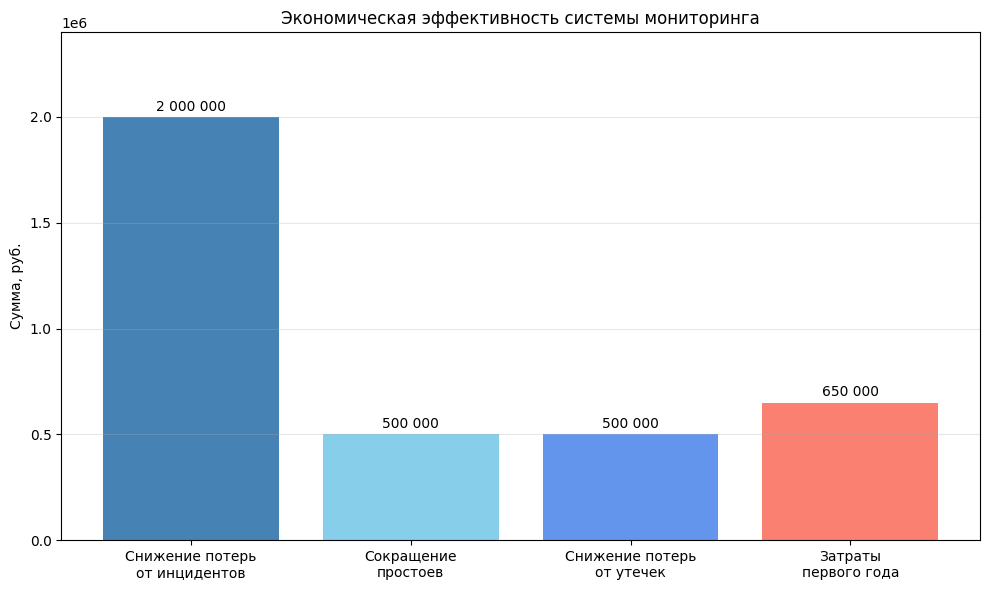

ROI первого года: 361.54%
Чистый экономический эффект: 2,350,000 руб.


In [8]:

# Шаг 7. Визуализация экономической эффективности

import matplotlib.pyplot as plt

categories = [
    "Снижение потерь\nот инцидентов",
    "Сокращение\nпростоев",
    "Снижение потерь\nот утечек",
    "Затраты\nпервого года"
]

values = [
    incident_savings,
    downtime_savings,
    data_leak_savings,
    total_costs
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    categories,
    values,
    color=["steelblue", "skyblue", "cornflowerblue", "salmon"]
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 30000,
        f"{height:,.0f}".replace(",", " "),
        ha="center",
        fontsize=10
    )

plt.title("Экономическая эффективность системы мониторинга")
plt.ylabel("Сумма, руб.")
plt.ylim(0, max(values) * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("roi_analysis.png", dpi=150)
plt.show()

print(f"ROI первого года: {roi:.2f}%")
print(f"Чистый экономический эффект: {net_benefit:,.0f} руб.")


### Анализ результатов экономической эффективности

В результате расчёта установлено, что совокупная годовая экономия от внедрения системы мониторинга сетевого трафика составляет 3 000 000 руб.

Наибольший экономический эффект достигается за счёт сокращения потерь от инцидентов информационной безопасности и составляет 2 000 000 руб.

Экономия вследствие сокращения времени простоя предприятия составляет 500 000 руб. Дополнительное снижение потерь от утечек конфиденциальных данных оценивается в 500 000 руб.

При затратах первого года в размере 650 000 руб. чистый экономический эффект составляет 2 350 000 руб., а показатель ROI достигает 361,54%.

Таким образом, при принятых учебных допущениях внедрение системы мониторинга сетевого трафика является экономически целесообразным.

## 7. Заключение

В ходе выполнения практического задания к лекции №7 была разработана и усовершенствована система мониторинга сетевого трафика предприятия «ТехноПрофи» с использованием языка программирования Python и среды Google Colab.

В рамках первого задания реализован алгоритм обнаружения потенциальных DDoS-атак на основе анализа количества пакетов в секунду. При моделировании аномальной сетевой активности система успешно обнаружила превышение установленного порога и сформировала предупреждение с уровнем опасности HIGH.

Также реализован механизм ведения журнала аудита событий безопасности в формате JSONL и разработана система формирования уведомлений с возможностью отправки через Telegram Bot API. Проверка уведомлений проведена в демонстрационном режиме.

В рамках второго задания выполнена оценка экономической эффективности внедрения системы мониторинга. На основе условных данных установлено, что годовая экономия составляет 3 000 000 руб., чистый экономический эффект первого года — 2 350 000 руб., а ROI — 361,54%.

Таким образом, поставленные задачи по разработке и тестированию учебного прототипа выполнены. Полученные результаты демонстрируют возможности автоматизированного обнаружения сетевых угроз, регистрации событий безопасности и оценки экономической эффективности защитных мероприятий.

### Обоснование исходных данных

Согласно исследованию IBM и Ponemon Institute «Cost of a Data Breach Report 2025», средняя мировая стоимость утечки данных составляет 4,44 млн долларов США.

Поскольку предприятие «ТехноПрофи» является условным предприятием среднего бизнеса с численностью 200 сотрудников, для учебного расчёта принята условная стоимость одного инцидента безопасности в размере 1 000 000 руб.

Данные исследования используются как ориентир для оценки значимости финансовых рисков. Остальные экономические показатели являются модельными. Для исключения двойного учёта предполагается, что расходы на устранение инцидентов, потери от простоев и утечек данных не пересекаются.

Источник: IBM, Ponemon Institute. Cost of a Data Breach Report 2025.

https://www.ibm.com/think/x-force/2025-cost-of-a-data-breach-navigating-ai

In [9]:
from google.colab import files

files.download("audit_log.jsonl")
files.download("ddos_detection.png")
files.download("roi_analysis.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>